# Titanic Dataset — Summary Table

| Feature        | Type               | Description |
|----------------|--------------------|-------------|
| **survived**   | Binary (0/1)       | Passenger survival (0 = no, 1 = yes). |
| **pclass**     | Categorical (1/2/3)| Passenger ticket class (proxy for socio-economic status). |
| **sex**        | Categorical        | Gender of the passenger (`male`, `female`). |
| **age**        | Continuous (float) | Age of the passenger (in years). Missing for some. |
| **sibsp**      | Integer            | Number of siblings/spouses aboard. |
| **parch**      | Integer            | Number of parents/children aboard. |
| **fare**       | Continuous (float) | Ticket price (in 1912 British pounds). |
| **embarked**   | Categorical        | Port of embarkation (`C` = Cherbourg, `Q` = Queenstown, `S` = Southampton). |
| **class**      | Categorical        | Passenger class (`First`, `Second`, `Third`). |
| **who**        | Categorical        | Simplified category (`man`, `woman`, `child`). |
| **adult_male** | Boolean            | Whether passenger is an adult male (`True`/`False`). |
| **deck**       | Categorical        | Cabin deck letter (`A–G` or missing). |
| **embark_town**| String             | Embarkation town name (`Cherbourg`, `Queenstown`, `Southampton`). |
| **alive**      | String             | Human-readable survival status (`yes`, `no`). |
| **alone**      | Boolean            | True if passenger had no family aboard. |


# 1. Imports

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
import joblib

# 2. Load Titanic Dataset

In [2]:
import seaborn as sns
titanic = sns.load_dataset("titanic")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2.1 Checking Data Quality
Before feature engineering, profile the raw data and assess four quality dimensions:

- **Missingness:** count and pattern by column; decide whether absence is meaningful.
- **Duplicates:** check repeated records and key uniqueness; identical attributes do not prove the same entity.
- **Invalid or inconsistent values:** verify types, categories, units, formats, ranges, and cross-column rules.
- **Outliers:** flag unusual values and investigate them against domain limits and source records. An outlier is a candidate for review, not an automatic deletion.

Run these checks before cleaning, record their results, and choose a treatment with a stated rationale.


In [3]:
# --- Checking Data Quality ---

# 1. Overview of data types and non-null counts
print("=== Dataset Info ===")
print(titanic.info())


=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None


In [ ]:
# Missingness profile: frequency by column and number of missing fields per row.
missing_by_column = pd.DataFrame({
    "missing_count": titanic.isna().sum(),
    "missing_percent": 100 * titanic.isna().mean(),
}).sort_values("missing_percent", ascending=False)
display(missing_by_column.round(2))

missing_fields_per_row = titanic.isna().sum().value_counts().sort_index()
missing_fields_per_row.index.name = "number of missing fields in row"
missing_fields_per_row.name = "row count"
display(missing_fields_per_row.to_frame())

In [ ]:
# Exact duplicate rows are candidates for review, not automatic deletions.
duplicate_count = int(titanic.duplicated().sum())
print("Exact duplicate-looking rows:", duplicate_count)
print("This dataset has no trusted passenger identifier: equal feature values alone do not establish that two rows describe the same person.")


In [6]:

# 4. Basic statistics
print("\n=== Descriptive Statistics ===")
display(titanic.describe(include="all").transpose())


=== Descriptive Statistics ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1.1 Schema, domain, and consistency checks
Check that values fall within the dataset's documented domains and that related columns agree. These checks count violations while ignoring missing values, which are assessed separately above.

In [ ]:
# Domain checks: allowed categories and plausible numeric ranges.
checks = {}
allowed_values = {
    "survived": {0, 1},
    "pclass": {1, 2, 3},
    "sex": {"male", "female"},
    "embarked": {"C", "Q", "S"},
    "deck": set("ABCDEFG"),
}
for column, allowed in allowed_values.items():
    observed = titanic[column].dropna()
    checks[f"{column}: outside allowed values"] = int((~observed.isin(allowed)).sum())

for column in ["sibsp", "parch", "fare"]:
    checks[f"{column}: negative values"] = int((titanic[column].dropna() < 0).sum())
checks["age: outside 0–100 years"] = int((~titanic["age"].dropna().between(0, 100)).sum())

# Cross-column consistency checks.
expected_class = titanic["pclass"].map({1: "First", 2: "Second", 3: "Third"})
mask = titanic["pclass"].notna() & titanic["class"].notna()
checks["class disagrees with pclass"] = int((titanic.loc[mask, "class"].astype("string") != expected_class.loc[mask].astype("string")).sum())

expected_town = titanic["embarked"].map({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"})
mask = titanic["embarked"].notna() & titanic["embark_town"].notna()
checks["embark_town disagrees with embarked"] = int((titanic.loc[mask, "embark_town"].astype("string") != expected_town.loc[mask].astype("string")).sum())

expected_alive = titanic["survived"].map({0: "no", 1: "yes"})
mask = titanic["survived"].notna() & titanic["alive"].notna()
checks["alive disagrees with survived"] = int((titanic.loc[mask, "alive"].astype("string") != expected_alive.loc[mask].astype("string")).sum())

expected_alone = (titanic["sibsp"] + titanic["parch"] == 0)
mask = titanic["sibsp"].notna() & titanic["parch"].notna() & titanic["alone"].notna()
checks["alone disagrees with sibsp/parch"] = int((titanic.loc[mask, "alone"] != expected_alone.loc[mask]).sum())

display(pd.Series(checks, name="Violations").to_frame())

### 2.1.2 Outlier screening
Use robust summaries and visual inspection to flag candidates. The IQR rule is a screening aid: high fares or ages can be valid, so investigate flagged rows before correcting, capping, transforming, or removing anything.

In [ ]:
# IQR flags for continuous features; a flag does not mean the value is invalid.
outlier_summary = []
for column in ["age", "fare"]:
    values = titanic[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (values < lower) | (values > upper)
    outlier_summary.append({
        "feature": column,
        "IQR lower bound": lower,
        "IQR upper bound": upper,
        "candidate count": int(flagged.sum()),
        "candidate percent": 100 * flagged.mean(),
    })
display(pd.DataFrame(outlier_summary).set_index("feature").round(2))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, column in zip(axes, ["age", "fare"]):
    sns.boxplot(x=titanic[column], ax=ax, color="steelblue")
    ax.set_title(f"{column}: inspect flagged values")
plt.tight_layout()
plt.show()

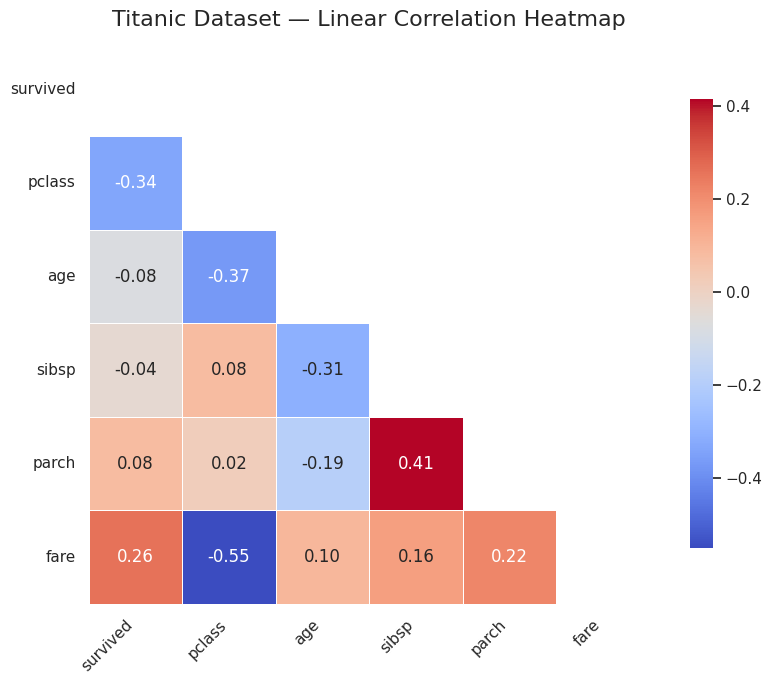

In [7]:
# Apply seaborn theme
sns.set_theme(style="white")

# Select numeric features
numeric_df = titanic.select_dtypes(include=["int64", "float64"])

# Compute correlation matrix
corr = numeric_df.corr(numeric_only=True)

# Generate a mask for the upper triangle
mask = np.triu(corr)

# Set up the matplotlib figure
plt.figure(figsize=(9,7))

# Draw the heatmap
sns.heatmap(
    corr, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    cbar_kws={"shrink": .8}, 
    linewidths=0.5, 
    square=True
)

plt.title("Titanic Dataset — Linear Correlation Heatmap", fontsize=16, pad=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Data Cleaning

Keep rows only when the target is observed; the target cannot be imputed. For `deck` and `embark_town`, retain missingness as an explicit `Unknown` category because it can carry information. Leave `age` and `embarked` missing here: their median/mode imputers will be fitted on the training partition inside the preprocessing pipeline, avoiding information leakage.


In [8]:
# Remove rows with an unknown target; preserve the remaining feature missingness.
titanic = titanic.dropna(subset=["survived"]).copy()

# Explicit category: this is a declared representation, not a statistic learned from all rows.
for col in ["deck", "embark_town"]:
    titanic[col] = titanic[col].astype("category")
    titanic[col] = titanic[col].cat.add_categories("Unknown")
    titanic[col] = titanic[col].fillna("Unknown")

# Do not fill age or embarked here. SimpleImputer will learn from X_train when the pipeline is fitted below.


# 4. Feature Creation

In [9]:
titanic["family_size"] = titanic["sibsp"] + titanic["parch"] + 1
titanic["is_alone"] = (titanic["family_size"] == 1).astype(int)
titanic["title"] = titanic["who"].map(
    {"man": "Mr", "woman": "Mrs", "child": "Master"}
)

titanic[["survived","family_size","is_alone","title"]].head()

,survived,family_size,is_alone,title
0,0,2,0,Mr
1,1,2,0,Mrs
2,1,1,1,Mrs
3,1,2,0,Mrs
4,0,1,1,Mr


# 5. Define Features and Target

In [10]:

X = titanic[
    ["pclass","sex","age","fare","embarked","family_size","is_alone","title"]
]
y = titanic["survived"]


In [ ]:
# Apply seaborn theme
sns.set_theme(style="white")

# Select numeric features
numeric_df = X.select_dtypes(include=["int64", "float64"]).join(y)

# Compute correlation matrix
corr = numeric_df.corr(numeric_only=True)

# Generate a mask for the upper triangle
mask = np.triu(corr)

# Set up the matplotlib figure
plt.figure(figsize=(9,7))

# Draw the heatmap
sns.heatmap(
    corr, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    cbar_kws={"shrink": .8}, 
    linewidths=0.5, 
    square=True
)

plt.title("Titanic Dataset — Linear Correlation Heatmap", fontsize=16, pad=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import chi2_contingency

# Select categorical features (excluding numeric)
cat_features = titanic.select_dtypes(include=["object", "category", "bool"]).copy()

# Target variable
y = titanic["survived"].astype(int)

# Chi-squared test of independence: one contingency table (feature x target) per feature.
# Note: sklearn.feature_selection.chi2 treats feature values as non-negative counts;
# applied to label-encoded nominal variables it does NOT compute this test, and its
# score would depend on the arbitrary integer codes.
results = []
for col in cat_features.columns:
    table = pd.crosstab(cat_features[col].astype(str), y)
    chi2_stat, p_value, dof, _ = chi2_contingency(table, correction=False)
    results.append({"Feature": col, "Chi2 Score": chi2_stat, "dof": dof, "p-value": p_value})

chi_results = pd.DataFrame(results).sort_values("Chi2 Score", ascending=False)

# --- Plot results ---
# 'alive' restates the target (yes/no), so it is excluded from the plot: it is target leakage.
plt.figure(figsize=(8,5))
sns.barplot(
    data=chi_results[chi_results["Feature"] != "alive"],
    x="Chi2 Score",
    y="Feature",
    hue="Feature",
    palette="viridis"
)
plt.title("Chi-Squared Test of Independence: Categorical Features vs Survived", fontsize=14, pad=10)
plt.xlabel("Chi² statistic (higher = stronger association)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

chi_results

**Reading the ranking**

- `alive` obtains the maximum score ($\chi^2 = n$): it restates the target, so it is **target leakage** and must be removed by inspection, not by score.
- `embarked` and `embark_town` obtain identical scores: they encode the same information, so one of them is redundant.
- `who` and `title` obtain identical scores: `title` is a one-to-one relabelling of `who` and adds no information.
- A univariate filter scores each feature in isolation; it cannot detect redundancy between features (e.g. `sex`, `who`, `adult_male`).

# 6. Feature Selection Example

`is_alone` is a deterministic function of `family_size` (`is_alone = 1` exactly when `family_size == 1`), so it carries **no additional information**. However, survival is **non-monotonic** in `family_size`, so a linear model cannot reproduce the indicator by itself. Redundancy therefore depends on the model family: we inspect the relationship before deciding.

In [13]:
# is_alone is a deterministic function of family_size
print(pd.crosstab(X["family_size"], X["is_alone"]))

# ... but its linear association with the target is much stronger
print(X[["family_size", "is_alone"]].join(y).corr()["survived"])

# Survival rate is non-monotonic in family_size
print(titanic.groupby("family_size")["survived"].mean().round(2))

# Decision: keep is_alone, because the next model (logistic regression) is linear
X_selected = X.copy()
print(X_selected.shape)

is_alone       0    1
family_size          
1              0  537
2            161    0
3            102    0
4             29    0
5             15    0
6             22    0
7             12    0
8              6    0
11             7    0
family_size    0.016639
is_alone      -0.203367
survived       1.000000
Name: survived, dtype: float64
family_size
1     0.30
2     0.55
3     0.58
4     0.72
5     0.20
6     0.14
7     0.33
8     0.00
11    0.00
Name: survived, dtype: float64
(891, 8)


# 8. Train/Test Split



In [14]:
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 8)
(179, 8)
(712,)
(179,)


# 9. Preprocessing Pipelines ---

In [15]:

numeric_features = ["age","fare","family_size","is_alone"]
categorical_features = ["pclass","sex","embarked","title"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# 10. Full Pipeline with Logistic Regression

In [ ]:
print(X_train.shape)

clf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=100))
])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Accuracy (without PCA):", accuracy_score(y_test, y_pred))


# 11. Pipeline with Feature Extraction (PCA)

In [ ]:
pca_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("pca", PCA(n_components=3)),
    ("classifier", LogisticRegression(max_iter=100))
])

pca_pipeline.fit(X_train, y_train)
y_pred_pca = pca_pipeline.predict(X_test)

print("Accuracy (with PCA):", accuracy_score(y_test, y_pred_pca))

# 12. Save Pipelines (Serialization)

In [ ]:

joblib.dump(clf, "titanic_feature_pipeline.pkl")
joblib.dump(pca_pipeline, "titanic_pca_pipeline.pkl")


# --- 13. Reload & Predict ---

In [ ]:

loaded_clf = joblib.load("titanic_feature_pipeline.pkl")
print("Reloaded model accuracy:", accuracy_score(y_test, loaded_clf.predict(X_test)))


# 14. Summary
Key Takeaways:
- Feature Engineering includes creating new variables (family_size, titles).
- Feature Selection must consider the model family: `is_alone` is informationally redundant with `family_size`, but useful for a linear model.
- Filter scores (chi-squared test of independence) can rank leaking features first (`alive`); inspect before selecting.
- Feature Extraction (PCA) transforms data into lower dimensions.
- Pipelines ensure reproducibility and consistency in MLOps.
- Serialization (joblib) allows deployment-ready models.

